# OE2B-04 — Extracción de features de audio

Este notebook convierte cada archivo de audio en un **vector de números** que el modelo xnorC puede procesar.
Un modelo no puede trabajar directamente con audio crudo (una señal de millones de muestras) —
necesita una representación compacta que capture las características acústicas relevantes.

---

## ¿Qué representaciones usamos?

Probamos 4 representaciones distintas, una por experimento (ablation study):

| Código | Representación | Descripción breve |
|---|---|---|
| **B1** | Mel spectrogram | Espectrograma en escala Mel (imita la percepción humana del sonido) |
| **B2** | MFCC + Delta | Coeficientes cepstrales + su derivada temporal (captura timbre y dinámica) |
| **B3** | FFT bins (~30 Hz) | Espectro de frecuencias en resolución fina (compatible con MSPB) |
| **B4** | CQT | Transformada Q constante (buena para señales con estructura armónica) |

Cada representación se calcula para **todos los archivos** de Yang y NU-HIVE.
El resultado es un archivo `.npy` por representación con shape `(n_archivos, n_features)`.

---

## Preprocesamiento estándar

Antes de extraer features, todos los audios pasan por el mismo preprocesamiento:

1. **Resampleo a 8 kHz** — estándar mínimo para voz/audio de campo, reduce carga computacional
2. **Conversión a mono** — promediando canales si hay más de uno
3. **Normalización de amplitud** — escalar al rango [-1, +1]
4. **Truncado/padding a duración fija** — para que todos los vectores tengan el mismo tamaño

---

## Outputs

```
../data/processed/features/
  features_B1_mel.npy        ← matriz (n_archivos, n_features)
  features_B2_mfcc.npy
  features_B3_fft.npy
  features_B4_cqt.npy
  features_index.csv         ← mapeo índice → ruta de archivo (para cruzar con los pares)
```

**No modifica ningún archivo de audio.**

## Configuración

In [ ]:
from pathlib import Path

# ─── RUTAS ───────────────────────────────────────────────────────────────────
RUTA_INV_YANG   = Path("../data/processed/yang/yang_audio_inventario.csv")
RUTA_INV_NUHIVE = Path("../data/processed/nuhive/nuhive_inventario.csv")
RUTA_FEATURES   = Path("../data/processed/features")

# ─── PREPROCESAMIENTO ────────────────────────────────────────────────────────
SR_OBJETIVO      = 8000     # resampleo a 8 kHz
DURACION_SEG     = 60       # duración fija en segundos (Yang: 1 min por segmento)
N_MUESTRAS       = SR_OBJETIVO * DURACION_SEG   # = 480,000 muestras

# ─── PARÁMETROS DE FEATURES ──────────────────────────────────────────────────
# B1 — Mel spectrogram
N_FFT_MEL        = 512      # tamaño de ventana FFT
HOP_LENGTH_MEL   = 256      # salto entre ventanas
N_MELS           = 64       # número de bandas Mel

# B2 — MFCC + Delta
N_MFCC           = 20       # número de coeficientes MFCC
N_FFT_MFCC       = 512
HOP_LENGTH_MFCC  = 256

# B3 — FFT bins (~30 Hz de resolución)
# Con SR=8000 Hz y resolución ~30 Hz → N_FFT ≈ 8000/30 ≈ 266, redondeamos a 256
N_FFT_BIN        = 256
HOP_LENGTH_BIN   = 128

# B4 — CQT
N_BINS_CQT       = 72       # 6 octavas × 12 bins/octava (antes: 84 → excedía Nyquist)
BINS_PER_OCT_CQT = 12
FMIN_CQT         = 32.7     # C1 (Do grave) en Hz
HOP_LENGTH_CQT   = 256

# ─── CONTROL DE EJECUCIÓN ────────────────────────────────────────────────────
# Poner en False las representaciones que no querés calcular ahora
CALCULAR_B1_MEL  = True
CALCULAR_B2_MFCC = True
CALCULAR_B3_FFT  = True
CALCULAR_B4_CQT  = True
# ─────────────────────────────────────────────────────────────────────────────

RUTA_FEATURES.mkdir(parents=True, exist_ok=True)
print("Configuración lista")
print(f"  SR objetivo:    {SR_OBJETIVO} Hz")
print(f"  Duración fija:  {DURACION_SEG} seg ({N_MUESTRAS:,} muestras)")

Configuración lista
  SR objetivo:    8000 Hz
  Duración fija:  60 seg (480,000 muestras)


## Importaciones

In [7]:
import pandas as pd
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

print(f"librosa version: {librosa.__version__}")
print("Importaciones listas")

librosa version: 0.11.0
Importaciones listas


---
## 1. Cargar inventarios y construir lista de archivos

Cargamos los inventarios de Yang y NU-HIVE y construimos una lista única de archivos.
Solo usamos archivos con etiqueta QR o QL — los sin etiqueta no sirven para entrenar.

In [8]:
df_yang   = pd.read_csv(RUTA_INV_YANG)
df_nuhive = pd.read_csv(RUTA_INV_NUHIVE)

df_yang['dataset']   = 'yang'
df_nuhive['dataset'] = 'nuhive'

# Solo archivos con etiqueta
df_all = pd.concat([
    df_yang[df_yang['estado'].notna()],
    df_nuhive[df_nuhive['estado'].notna()]
], ignore_index=True)

# Índice secuencial — es el que vamos a usar para indexar las matrices de features
df_all = df_all.reset_index(drop=True)
df_all.index.name = 'feature_idx'

# Guardar el índice → ruta para cruzar con los pares después
df_index = df_all[['ruta', 'dataset', 'estado']].copy()
df_index.to_csv(RUTA_FEATURES / 'features_index.csv')

print(f"Total archivos a procesar: {len(df_all):,}")
print()
print(df_all.groupby(['dataset', 'estado']).size().rename('n').to_string())

Total archivos a procesar: 7,676

dataset  estado
nuhive   QL         288
         QR         288
yang     QL        2499
         QR        4601


---
## 2. Función de preprocesamiento

Esta función carga un archivo de audio y lo deja listo para extraer features:
resamplea, convierte a mono, normaliza y ajusta la duración.

In [9]:
def cargar_audio(ruta, sr_objetivo=SR_OBJETIVO, n_muestras=N_MUESTRAS):
    """
    Carga un archivo de audio y lo preprocesa:
      1. Carga con soundfile (soporta WAV float32)
      2. Convierte a mono (promedia canales)
      3. Resamplea a sr_objetivo
      4. Normaliza amplitud a [-1, +1]
      5. Trunca o rellena con ceros a n_muestras

    Devuelve: array numpy de shape (n_muestras,) o None si hay error.
    """
    try:
        # Cargar audio (soundfile devuelve shape (n_muestras, n_canales) o (n_muestras,))
        audio, sr_orig = sf.read(ruta, always_2d=False)

        # Convertir a mono si tiene varios canales
        if audio.ndim > 1:
            audio = audio.mean(axis=1)

        # Convertir a float32
        audio = audio.astype(np.float32)

        # Resamplear si es necesario
        if sr_orig != sr_objetivo:
            audio = librosa.resample(audio, orig_sr=sr_orig, target_sr=sr_objetivo)

        # Normalizar amplitud a [-1, +1]
        max_amp = np.abs(audio).max()
        if max_amp > 0:
            audio = audio / max_amp

        # Ajustar duración: truncar si es más largo, rellenar con ceros si es más corto
        if len(audio) >= n_muestras:
            audio = audio[:n_muestras]
        else:
            audio = np.pad(audio, (0, n_muestras - len(audio)))

        return audio

    except Exception as e:
        print(f"⚠️  Error cargando {ruta}: {e}")
        return None


# Prueba rápida con el primer archivo
ruta_prueba = df_all['ruta'].iloc[0]
audio_prueba = cargar_audio(ruta_prueba)
if audio_prueba is not None:
    print(f"Prueba OK: {Path(ruta_prueba).name}")
    print(f"  Shape: {audio_prueba.shape}")
    print(f"  Min/Max: {audio_prueba.min():.3f} / {audio_prueba.max():.3f}")
    print(f"  Dtype: {audio_prueba.dtype}")

Prueba OK: 2022-06-05--17-41-01_2__segment0.wav
  Shape: (480000,)
  Min/Max: -1.000 / 0.978
  Dtype: float32


---
## 3. Funciones de extracción de features

Una función por representación. Cada función recibe el audio preprocesado
y devuelve un vector 1D (promedio temporal del espectrograma).

El promedio temporal convierte el espectrograma 2D (tiempo × frecuencia) en un
vector 1D (frecuencia), lo que da una representación compacta de todo el fragmento.
Para Yang, que tiene segmentos de 1 minuto, esto es apropiado.
Para NU-HIVE, con segmentos de ~10 minutos, también captura bien el estado promedio.

In [10]:
def extraer_B1_mel(audio, sr=SR_OBJETIVO):
    """
    B1 — Mel spectrogram.
    Calcula el espectrograma en escala Mel y promedia en el tiempo.
    Devuelve vector de shape (N_MELS,) = (64,)
    """
    S = librosa.feature.melspectrogram(
        y=audio, sr=sr,
        n_fft=N_FFT_MEL, hop_length=HOP_LENGTH_MEL,
        n_mels=N_MELS
    )
    # Convertir a dB (escala logarítmica) y promediar en el tiempo
    S_db = librosa.power_to_db(S, ref=np.max)
    return S_db.mean(axis=1).astype(np.float32)   # shape: (N_MELS,)


def extraer_B2_mfcc(audio, sr=SR_OBJETIVO):
    """
    B2 — MFCC + Delta.
    Calcula N_MFCC coeficientes cepstrales + su derivada temporal (delta).
    Promedia en el tiempo y concatena ambos.
    Devuelve vector de shape (N_MFCC * 2,) = (40,)
    """
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT_MFCC, hop_length=HOP_LENGTH_MFCC
    )
    delta = librosa.feature.delta(mfcc)   # derivada temporal
    # Promediar en el tiempo y concatenar
    vec = np.concatenate([
        mfcc.mean(axis=1),
        delta.mean(axis=1)
    ])
    return vec.astype(np.float32)   # shape: (N_MFCC*2,)


def extraer_B3_fft(audio, sr=SR_OBJETIVO):
    """
    B3 — FFT bins en resolución ~30 Hz.
    Calcula el espectro de amplitud promedio del fragmento.
    Devuelve vector de shape (N_FFT_BIN//2 + 1,) = (129,)
    """
    S = np.abs(librosa.stft(
        audio,
        n_fft=N_FFT_BIN, hop_length=HOP_LENGTH_BIN
    ))
    # Promediar en el tiempo
    return S.mean(axis=1).astype(np.float32)   # shape: (N_FFT_BIN//2 + 1,)


def extraer_B4_cqt(audio, sr=SR_OBJETIVO):
    """
    B4 — CQT (Constant-Q Transform).
    Resolución logarítmica en frecuencia, útil para señales armónicas (zumbido de abejas).
    Devuelve vector de shape (N_BINS_CQT,) = (84,)
    """
    C = np.abs(librosa.cqt(
        audio, sr=sr,
        hop_length=HOP_LENGTH_CQT,
        fmin=FMIN_CQT,
        n_bins=N_BINS_CQT,
        bins_per_octave=BINS_PER_OCT_CQT
    ))
    return C.mean(axis=1).astype(np.float32)   # shape: (N_BINS_CQT,)


# Verificar shapes con el audio de prueba
if audio_prueba is not None:
    print("Shapes de features (audio de prueba):")
    print(f"  B1 Mel:  {extraer_B1_mel(audio_prueba).shape}")
    print(f"  B2 MFCC: {extraer_B2_mfcc(audio_prueba).shape}")
    print(f"  B3 FFT:  {extraer_B3_fft(audio_prueba).shape}")
    print(f"  B4 CQT:  {extraer_B4_cqt(audio_prueba).shape}")

Shapes de features (audio de prueba):
  B1 Mel:  (64,)
  B2 MFCC: (40,)


  B3 FFT:  (129,)
  B4 CQT:  (72,)


---
## 4. Extraer features para todos los archivos

Procesamos todos los archivos del inventario y guardamos una matriz `.npy` por representación.
La barra de progreso muestra cuánto falta.

**Tiempo estimado:** ~1-3 minutos por representación dependiendo del hardware y la cantidad de archivos.

In [11]:
def procesar_todos(df, funciones_features, sr=SR_OBJETIVO, n_muestras=N_MUESTRAS):
    """
    Procesa todos los archivos del inventario y extrae features.

    'funciones_features' es un dict {nombre: funcion_extraccion}.
    Devuelve un dict {nombre: matriz_numpy} donde cada matriz tiene
    shape (n_archivos, n_features).
    """
    n = len(df)
    matrices = {}   # nombre → lista de vectores
    errores  = []

    for nombre in funciones_features:
        matrices[nombre] = [None] * n

    for i, (_, fila) in enumerate(tqdm(df.iterrows(), total=n, desc="Extrayendo features")):
        audio = cargar_audio(fila['ruta'], sr_objetivo=sr, n_muestras=n_muestras)

        if audio is None:
            errores.append(i)
            # Rellena con ceros para mantener el índice alineado
            for nombre, fn in funciones_features.items():
                vec_prueba = fn(np.zeros(n_muestras, dtype=np.float32))
                matrices[nombre][i] = np.zeros_like(vec_prueba)
            continue

        for nombre, fn in funciones_features.items():
            try:
                matrices[nombre][i] = fn(audio)
            except Exception as e:
                print(f"⚠️  Error en {nombre} para {fila['ruta']}: {e}")
                errores.append(i)

    if errores:
        print(f"⚠️  {len(errores)} archivos con error (rellenos con ceros)")

    # Convertir listas a matrices numpy
    return {nombre: np.array(vecs) for nombre, vecs in matrices.items()}


# Armar el dict de funciones según lo que se quiera calcular
funciones = {}
if CALCULAR_B1_MEL:  funciones['B1_mel']  = extraer_B1_mel
if CALCULAR_B2_MFCC: funciones['B2_mfcc'] = extraer_B2_mfcc
if CALCULAR_B3_FFT:  funciones['B3_fft']  = extraer_B3_fft
if CALCULAR_B4_CQT:  funciones['B4_cqt']  = extraer_B4_cqt

print(f"Representaciones a calcular: {list(funciones.keys())}")
print(f"Total archivos: {len(df_all):,}")
print()

matrices = procesar_todos(df_all, funciones)

print()
print("Shapes resultantes:")
for nombre, mat in matrices.items():
    print(f"  {nombre}: {mat.shape}")

Representaciones a calcular: ['B1_mel', 'B2_mfcc', 'B3_fft', 'B4_cqt']
Total archivos: 7,676



Extrayendo features: 100%|██████████| 7676/7676 [56:27<00:00,  2.27it/s]  


Shapes resultantes:
  B1_mel: (7676, 64)
  B2_mfcc: (7676, 40)
  B3_fft: (7676, 129)
  B4_cqt: (7676, 72)


---
## 5. Guardar matrices de features

In [12]:
for nombre, mat in matrices.items():
    ruta_out = RUTA_FEATURES / f"features_{nombre}.npy"
    np.save(ruta_out, mat)
    print(f"Guardado: {ruta_out}  shape={mat.shape}  size={ruta_out.stat().st_size/1e6:.1f} MB")

print()
print(f"Índice guardado en: {RUTA_FEATURES / 'features_index.csv'}")

Guardado: ../data/processed/features/features_B1_mel.npy  shape=(7676, 64)  size=2.0 MB
Guardado: ../data/processed/features/features_B2_mfcc.npy  shape=(7676, 40)  size=1.2 MB
Guardado: ../data/processed/features/features_B3_fft.npy  shape=(7676, 129)  size=4.0 MB
Guardado: ../data/processed/features/features_B4_cqt.npy  shape=(7676, 72)  size=2.2 MB

Índice guardado en: ../data/processed/features/features_index.csv


---
## 6. Visualizar features promedio QR vs QL

Para cada representación, graficamos el vector promedio de QR y el de QL.
Si las dos curvas son distintas, el modelo tiene señal para aprender.
Si son idénticas, esa representación no sirve para distinguir los estados.

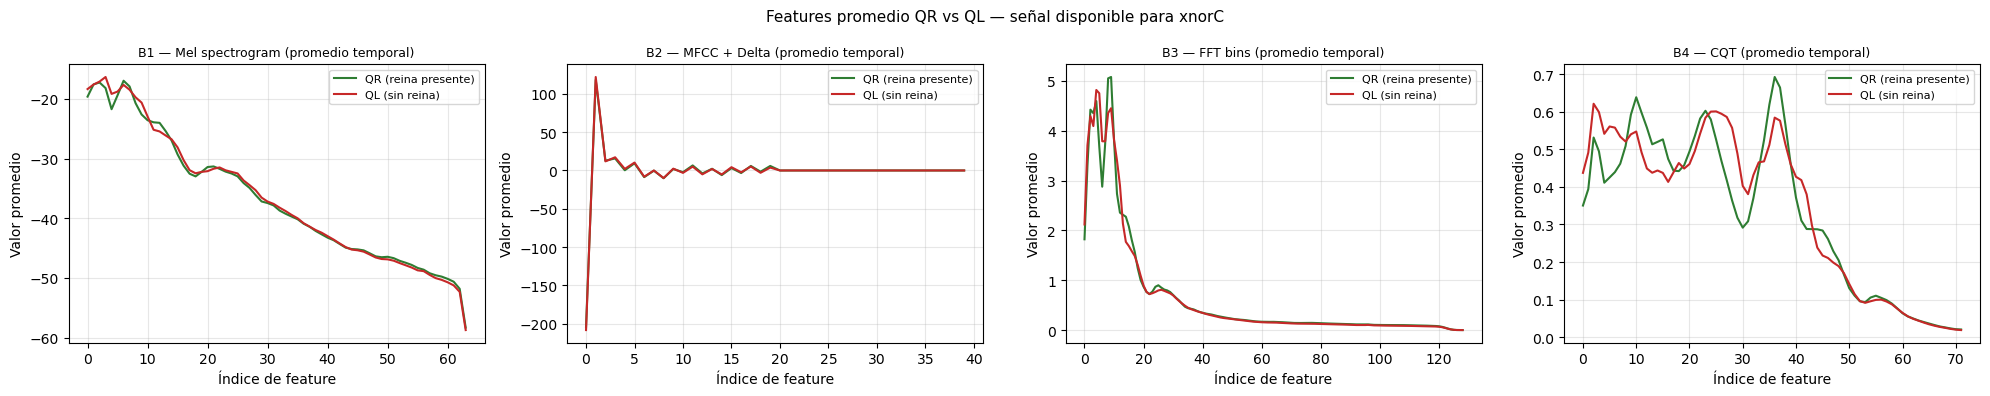


Interpretación:
  Curvas muy separadas → buena señal para distinguir QR/QL
  Curvas superpuestas  → poca señal, esa representación puede no ser útil


In [13]:
idx_qr = df_all[df_all['estado'] == 'QR'].index.tolist()
idx_ql = df_all[df_all['estado'] == 'QL'].index.tolist()

n_rep = len(matrices)
fig, axes = plt.subplots(1, n_rep, figsize=(5 * n_rep, 4))
if n_rep == 1:
    axes = [axes]

titulos = {
    'B1_mel':  'B1 — Mel spectrogram (promedio temporal)',
    'B2_mfcc': 'B2 — MFCC + Delta (promedio temporal)',
    'B3_fft':  'B3 — FFT bins (promedio temporal)',
    'B4_cqt':  'B4 — CQT (promedio temporal)',
}

for ax, (nombre, mat) in zip(axes, matrices.items()):
    prom_qr = mat[idx_qr].mean(axis=0)
    prom_ql = mat[idx_ql].mean(axis=0)

    ax.plot(prom_qr, color='#2E7D32', label='QR (reina presente)', linewidth=1.5)
    ax.plot(prom_ql, color='#C62828', label='QL (sin reina)',       linewidth=1.5)
    ax.set_title(titulos.get(nombre, nombre), fontsize=9)
    ax.set_xlabel('Índice de feature')
    ax.set_ylabel('Valor promedio')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Features promedio QR vs QL — señal disponible para xnorC', fontsize=11)
plt.tight_layout()
plt.show()

print()
print("Interpretación:")
print("  Curvas muy separadas → buena señal para distinguir QR/QL")
print("  Curvas superpuestas  → poca señal, esa representación puede no ser útil")

B1 — Mel spectrogram: Las curvas QR y QL son casi idénticas. Hay muy poca diferencia visual. El promedio temporal aplana demasiado la información — el Mel spectrogram probablemente tenga señal útil en la dimensión temporal (cómo cambia la energía a lo largo del minuto), pero al promediar todo en un solo vector la perdemos.

B2 — MFCC + Delta: Igual que B1 — las curvas están prácticamente superpuestas. El MFCC tiene el mismo problema: la diferencia entre QR y QL no está en el timbre promedio sino en la dinámica temporal.

B3 — FFT bins: Las curvas están muy pegadas excepto en las frecuencias bajas (índices 0–15, que corresponden a 0–470 Hz aproximadamente). Ahí hay una diferencia pequeña pero visible. Es la mejor señal de las primeras tres representaciones, pero sigue siendo débil.

B4 — CQT: Es la que muestra más separación entre QR y QL. Las curvas divergen claramente en varias bandas, especialmente alrededor de los índices 20–40 (frecuencias medias). Esto tiene sentido biológico: el zumbido de las abejas tiene estructura armónica, y el CQT está diseñado exactamente para capturar eso.

**Conclusión práctica para la tesis:**

El promedio temporal es una representación demasiado agresiva — colapsa 60 segundos en un solo vector y pierde la dinámica. Para xnorC habría que considerar pasar el espectrograma 2D completo (tiempo × frecuencia) como entrada en lugar del promedio, especialmente para B1 y B2.

B4 (CQT) es el candidato más prometedor con esta representación de promedio. B3 (FFT) tiene algo de señal en bajas frecuencias. B1 y B2 con promedio temporal probablemente van a dar resultados pobres.

¿Querés ajustar la extracción para pasar el espectrograma 2D completo en lugar del promedio, o seguimos con lo que hay y lo verificamos con los resultados del modelo?


---
## 7. Resumen final

In [14]:
print("=" * 55)
print("RESUMEN FINAL — FEATURES (OE2B-04)")
print("=" * 55)
print(f"  Archivos procesados: {len(df_all):,}")
print(f"  SR objetivo:         {SR_OBJETIVO} Hz")
print(f"  Duración fija:       {DURACION_SEG} seg")
print()
print("  Representaciones guardadas:")
for nombre, mat in matrices.items():
    ruta_out = RUTA_FEATURES / f"features_{nombre}.npy"
    print(f"    {nombre}: shape={mat.shape}  ({ruta_out.stat().st_size/1e6:.1f} MB)")
print()
print("─── Próximo paso ───")
print("  OE2B-05: Entrenamiento de xnorC (experimentos B0–B4)")

RESUMEN FINAL — FEATURES (OE2B-04)
  Archivos procesados: 7,676
  SR objetivo:         8000 Hz
  Duración fija:       60 seg

  Representaciones guardadas:
    B1_mel: shape=(7676, 64)  (2.0 MB)
    B2_mfcc: shape=(7676, 40)  (1.2 MB)
    B3_fft: shape=(7676, 129)  (4.0 MB)
    B4_cqt: shape=(7676, 72)  (2.2 MB)

─── Próximo paso ───
  OE2B-05: Entrenamiento de xnorC (experimentos B0–B4)


---
## 8. Limitaciones y posibles mejoras

### Limitación principal: promedio temporal

La representación actual colapsa el espectrograma 2D (tiempo × frecuencia) en un vector 1D
promediando sobre el tiempo. Esto es rápido y simple, pero pierde información dinámica:
la diferencia entre QR y QL puede no estar en el **sonido promedio** sino en
**cómo cambia el sonido** a lo largo del tiempo (patrones rítmicos, modulaciones, eventos puntuales).

El gráfico de la sección 6 lo confirma: B1 y B2 muestran curvas QR/QL casi idénticas,
lo que sugiere que el promedio temporal aplana las diferencias.

### Mejoras posibles (trabajo futuro)

**Mejora 1 — Pasar el espectrograma 2D completo a xnorC**
En lugar de un vector de 64 números (B1), pasar una imagen de tamaño (64 × T) donde T
son los frames temporales. xnorC usaría una red CNN 2D en lugar de capas densas.
Esto preserva los patrones temporales y es el enfoque estándar en clasificación de audio.
Coste: mayor tiempo de entrenamiento y más parámetros.

**Mejora 2 — Estadísticas adicionales además del promedio**
En lugar de solo el promedio temporal, agregar la desviación estándar, el mínimo y el máximo
de cada banda. Esto captura variabilidad sin aumentar demasiado la dimensión del vector.
Ejemplo para B1: vector de 64 × 4 = 256 features en lugar de 64.
Coste: bajo — solo cambiar la función de extracción.

**Mejora 3 — Ventanas temporales cortas**
Dividir el fragmento de 60 segundos en ventanas de 5–10 segundos y extraer features de cada una.
xnorC compara secuencias de ventanas en lugar de un único vector.
Esto captura la evolución temporal sin necesitar una CNN 2D completa.

**Mejora 4 — Aumentar la resolución de CQT**
B4 mostró la mejor separación QR/QL. Usar `bins_per_octave=24` (cuartos de tono)
en lugar de 12 para capturar mejor las frecuencias armónicas del zumbido de abejas.

**Prioridad sugerida:** Mejora 2 es la más fácil de implementar y puede mejorar
significativamente los resultados sin cambiar la arquitectura del modelo.
Mejora 1 es la más poderosa pero requiere rediseñar xnorC.